# Compare multiple Hankel depths

Edit **Ks** in the configuration cell below, then Run All. Every chosen depth appears on one graph.


In [1]:
%matplotlib inline

import importlib
import qmboot
qmboot = importlib.reload(qmboot)
from IPython.display import display


## Edit your list of depths here

Choose unique integers >= 2. Large depths are limited by runtime and numerical precision.


In [ ]:
Ks = [10, 20, 50, 100,120, 150, 250]  # EDIT THIS LIST

potential = qmboot.PolynomialPotential({2: "1/2"})
display(potential.as_expr())

plot_boundary_digits = 2  # 0.01 energy-unit boundary resolution for this wide view.
table_relative_tolerance = 1e-5  # Relative width uncertainty target
table_boundary_digits = 12  # Table boundary resolution, independent of the plot.


x**2/2

## Show splitting up to the unresolved continuum

The energy axis expands automatically until the largest depth reaches its merged high-energy tail. Each row shows the separated bands, their count, and the approximate energy where they join an unresolved continuous region. This is a finite-depth resolution limit of the bootstrap; the physical harmonic oscillator spectrum remains discrete.

The calculation uses high-precision C++ arithmetic and a 0.01-unit plotting resolution. It identifies the tail through sampled positivity checks, so the reported onset and level count are numerical diagnostics rather than exact certificates. Matching results are cached in `.qmboot-cache`.


Loaded extended spectrum from cache


,K,separated_levels,last_separated_energy,tail_onset,tail_onset_uncertainty,runtime_seconds
0,10,2,1.5,1.964844,0.003906,0.047590
1,20,4,3.5,4.378906,0.003906,0.128338
2,50,14,13.5,14.199219,0.003906,0.959277
3,100,30,29.5,30.183594,0.003906,6.599587
4,120,36,35.5,36.285156,0.003906,11.196896
5,150,46,45.5,46.238281,0.003906,23.763145
6,250,78,77.5,78.316406,0.003906,102.081196


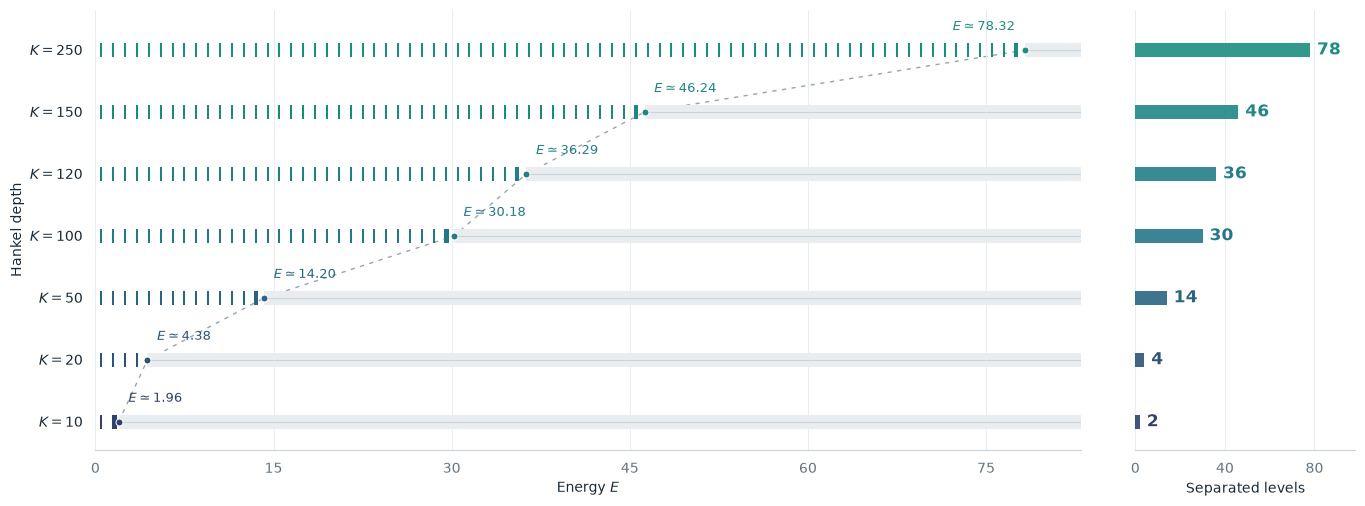

In [3]:
results, resolution = qmboot.spectrum_to_continuum(
    potential,
    Ks=Ks,
    boundary_digits=plot_boundary_digits,
    tail_padding=4,
)

display(resolution[[
    "K", "separated_levels", "last_separated_energy",
    "tail_onset", "tail_onset_uncertainty", "runtime_seconds",
]])
figure = qmboot.plot_spectrum_to_continuum(
    results, resolution, save_path="spectrum_extended.png"
)


## Energy intervals

The table always uses `max(Ks)`. All energies and widths are divided by $\omega$, with $\hbar=1$ and ground-state index $n=0$. $\epsilon_K=\max(|E_{\min}-E_{\mathrm{theory}}|,|E_{\max}-E_{\mathrm{theory}}|)/\omega$ measures the furthest endpoint error. Widths are upper limits; endpoints are numerical estimates at the table boundary resolution.


In [ ]:
table_K = max(Ks)

from pathlib import Path
import sympy as sp

omega = sp.sqrt(2 * potential.coefficients[2])  # mass = hbar = 1
highest_bands = results.loc[results.K == table_K]

if highest_bands.empty:
    if table_K not in set(resolution.K):
        raise ValueError("Run the spectrum cell with the current Ks first.")
    table_bands = highest_bands
else:
    table_bands = qmboot.spectral_sequence(
        potential,
        Ks=[table_K],
        Emin=str(potential.coefficients[0]),
        Emax=str(
            sp.Rational(str(highest_bands.E_level.max())) + omega / 2
        ),
        boundary_digits=table_boundary_digits,
        relative_width_tolerance=table_relative_tolerance,
        verify_precision=True,
        progress=True,
        cache_path=Path(".qmboot-cache") / f"table_adaptive_K{table_K}.csv",
    )

energy_levels = qmboot.energy_table(table_bands, potential, K=table_K)

print(
    f"K = {table_K}; energies in units of omega\n"
    f"Initial tolerance: 10^-{table_boundary_digits}; "
    f"relative width target: {table_relative_tolerance:.0e}"
)

if not table_bands.empty:
    limited = int(
        (~table_bands.relative_width_resolved.astype(bool)).sum()
    )
    print(f"{limited} level(s) remain resolution-limited upper limits.")


def scientific(value):
    mantissa, exponent = format(value, ".4E").split("E")
    return f"{mantissa} &times; 10<sup>{int(exponent)}</sup>"


formats = {
    column: scientific
    for column in energy_levels.columns
    if column != "Energy Level"
}
formats["Width upper bound"] = lambda value: "&le; " + scientific(value)

display(energy_levels.style.format(formats).hide(axis="index"))
energy_levels.to_csv(f"energy_levels_K{table_K}.csv", index=False)
```

Running K = 250 (high precision numerical)...


KeyboardInterrupt: 

## Optional matrix preview

This shows the matrix for the first depth in `Ks`; the graph includes all selected depths.


In [ ]:
bootstrap = qmboot.Bootstrap(potential, hankel_depth=Ks[0])
matrix = bootstrap.hankel(energy="1/2")
print(f"K = {Ks[0]}, full Hankel shape: {matrix.shape}")
display(matrix[:8, :8])


K = 10, full Hankel shape: (10, 10)


Matrix([
[   1,      0,    1/2,      0,    3/4,        0,     15/8,          0],
[   0,    1/2,      0,    3/4,      0,     15/8,        0,     105/16],
[ 1/2,      0,    3/4,      0,   15/8,        0,   105/16,          0],
[   0,    3/4,      0,   15/8,      0,   105/16,        0,     945/32],
[ 3/4,      0,   15/8,      0, 105/16,        0,   945/32,          0],
[   0,   15/8,      0, 105/16,      0,   945/32,        0,   10395/64],
[15/8,      0, 105/16,      0, 945/32,        0, 10395/64,          0],
[   0, 105/16,      0, 945/32,      0, 10395/64,        0, 135135/128]])

## Quartic potential

For $V(x)=x^2/2+x^4$, energy alone does not determine all moments. Supply or search the independent moment $\mu_2=\langle x^2\rangle$. For degree $d$, the independent moments are $\mu_2,\mu_4,\ldots,\mu_{d-2}$. C++ evaluates the recurrence and positivity with exact rationals. The following grid classifies sampled candidates; it does **not** certify continuous allowed intervals or rule out candidates between samples.

In [ ]:
quartic = qmboot.Bootstrap(
    qmboot.PolynomialPotential({2: "1/2", 4: 1}),
    hankel_depth=4,
)
print("Independent moment powers:", quartic.seed_powers)
display(quartic.hankel(energy=1, seed_moments={2: "1/3"}))

Independent moment powers: (2,)


Matrix([
[  1,   0, 1/3,      0],
[  0, 1/3,   0,    2/9],
[1/3,   0, 2/9,      0],
[  0, 2/9,   0, 47/180]])

In [ ]:
candidates = quartic.scan(
    energies=["4/5", "9/10", "1", "11/10", "6/5", "13/10"],
    seed_grids={2: ["1/5", "1/4", "3/10", "1/3", "2/5"]},
)
display(candidates)
display(candidates[candidates["positive_definite"]])

,K,energy,mu_2,positive_definite
0,4,0.8,0.200000,False
1,4,0.8,0.250000,True
2,4,0.8,0.300000,True
3,4,0.8,0.333333,True
4,4,0.8,0.400000,False
5,4,0.9,0.200000,False
6,4,0.9,0.250000,True
7,4,0.9,0.300000,True
8,4,0.9,0.333333,True
9,4,0.9,0.400000,True


,K,energy,mu_2,positive_definite
1,4,0.8,0.250000,True
2,4,0.8,0.300000,True
3,4,0.8,0.333333,True
6,4,0.9,0.250000,True
7,4,0.9,0.300000,True
8,4,0.9,0.333333,True
9,4,0.9,0.400000,True
12,4,1.0,0.300000,True
13,4,1.0,0.333333,True
14,4,1.0,0.400000,True


All implementation lives in `qmboot.py` and `native/bootstrap.cpp`. The notebook is a demonstration. The original symbolic notebook is saved as `QMBootstrap_Reference.ipynb`. After rebuilding the C++ extension, restart the kernel before importing it again.